# Tech Challenge - Fase 1: Análise de Expansão e Crescimento da Olist 
**(Grupo 58)**

## 1. Contexto e Pergunta de Negócio

**Pergunta Principal:** Onde estão as maiores oportunidades de expansão de receita da Olist, considerando o ticket médio e o impacto do frete?

**Justificativa Estratégica:**
No cenário do e-commerce brasileiro, o crescimento financeiro está diretamente atrelado à eficiência logística. Segundo um [levantamento publicado pela ABIACOM](https://abiacom.org/noticias/plataforma-de-intermediacao-de-fretes-e-ferramenta-importante-nas-vendas-online/), o frete é responsável por quase 66% dos custos logísticos de uma loja virtual, e o alto valor da entrega leva a 80% dos abandonos de carrinho. 

Como o modelo de negócios da Olist atua diretamente na intermediação e otimização desses contratos logísticos, através de soluções como o [Envios da Olist, que conecta pequenos e médios lojistas a transportadoras parceiras para otimizar custos](https://ajuda.olist.com/integracoes-e-automacao/envios-da-olist-%E2%80%94-guia-completo-de-integracao-e-uso), cruzar os dados de **Faturamento (Receita)** e **Frete (Custo)** me permite analisar onde estão as melhores oportunidades de expansão de mercado e onde o custo de envio pode estar atrapalhando as vendas.

In [605]:
# Manipulação dos dados
import pandas as pd
import numpy as np

# Visualização dos dados
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

print("Ferramentas importadas com sucesso!")

Ferramentas importadas com sucesso!


In [606]:
# Lendo a base de pedidos da Olist
df_orders = pd.read_csv('../data/olist_orders_dataset.csv')

# Exibir as 3 primeiras linhas
df_orders.head(3)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


## 2.Entendendo a Estrutura dos Dados

Para responder à pergunta de negócio, vou relacionar as bases da Olist, começando por:

**1. Tabela de Pedidos (`df_orders`):**
Ela é o "cabeçalho" da compra. Embora não contenha valores financeiros, possui colunas de status e data, sendo possível entender o histórico de cada caso para a análise.
* **`order_status`:** Que contém status como, por exemplo, status "delivered" que indica quais pedidos foram entregues.
* **`order_purchase_timestamp`:** O carimbo de data, que permite a análise ao longo do tempo (meses/anos).

In [607]:
# 1. Carregando a tabela de itens (onde estão os preços e fretes)
df_items = pd.read_csv('../data/olist_order_items_dataset.csv')

# 2. Descobrindo o tamanho da tabela (quantas linhas e colunas ela tem)
print(f"O tamanho da tabela de itens é: {df_items.shape}")

# 3. Exibindo apenas as 3 primeiras linhas para saber os dados da tabela. 
df_items.head(3)

O tamanho da tabela de itens é: (112650, 7)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


### 2.1 Entendendo as Variáveis: Itens (Faturamento e Frete)
Nesta segunda tabela (`df_items`), contém os seguintes indicadores: 

* **`price` (Preço do Produto):** que é uma **Variável Quantitativa Contínua**. 
  * *Na Estatística:* É "Quantitativa" pois é um número real que permite fazer operações matemáticas (como somar o faturamento total ou calcular a média). É "Contínua" porque o valor financeiro aceita quebras e frações (casas decimais, como R$ 29,90). 

* **`freight_value` (Valor do Frete):** Classificada como **Variável Quantitativa Contínua**. 
  * *Na Estatística:* Segue a mesma regra matemática do preço, sendo um valor financeiro que aceita frações decimais. Representa o custo logístico cobrado do cliente para a entrega.

In [608]:
# 1. Verificando se existem valores nulos (vazios) na tabela de itens (Faturamento e Frete)
print("Valores nulos na tabela de Itens:")
print(df_items.isnull().sum())

# 2. Verificando se existem valores nulos na tabela de pedidos (Datas e Status)
print("Valores nulos na tabela de Pedidos:")
print(df_orders.isnull().sum())

Valores nulos na tabela de Itens:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64
Valores nulos na tabela de Pedidos:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [609]:
# 1. Investigando os 160 pedidos sem aprovação de pagamento
print("**Status dos 160 pedidos sem Data de Aprovação **")
print(df_orders[df_orders['order_approved_at'].isnull()]['order_status'].value_counts())

print("\n**Status dos 1783 pedidos sem Envio para Transportadora **")
print(df_orders[df_orders['order_delivered_carrier_date'].isnull()]['order_status'].value_counts())

print("\n** Status dos 2965 pedidos sem Entrega ao Cliente **")
print(df_orders[df_orders['order_delivered_customer_date'].isnull()]['order_status'].value_counts())

**Status dos 160 pedidos sem Data de Aprovação **
order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64

**Status dos 1783 pedidos sem Envio para Transportadora **
order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2
Name: count, dtype: int64

** Status dos 2965 pedidos sem Entrega ao Cliente **
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


## 3. Qualidade e Preparação dos Dados (Data Cleaning)

A análise de valores nulos (`.isnull().sum()`) e a investigação de status acima revelaram que:
- **Dados Financeiros Intactos:** Não há valores ausentes nas colunas `price` e `freight_value` da tabela de itens.

Além disso, é possível ver que:
- **160** pedidos estão sem data de aprovação (`order_approved_at`) e o maior número é de cancelamentos. 
- **1783** pedidos sem data de envio para a transportadora (`order_delivered_carrier_date`), indicando indisponibilidade e cancelamento com os maiores números.
- **2965** pedidos sem data de entrega ao cliente (`order_delivered_customer_date`), com destaque para os pacotes ainda em trânsito (`shipped`), cancelados e indisponíveis.

Como os dados financeiros (preço e frete) e os dados de validação (status e datas) estão separados, o próximo passo é unir as duas tabelas. Para isso é possível utilizar a coluna `order_id`, pois ela é a chave identificadora comum entre ambas as bases. 

In [610]:
# Unindo as duas tabelas usando o 'order_id' como chave de conexão
df_merged = pd.merge(df_orders, df_items, on='order_id', how='inner')

# Exibindo o tamanho da nova tabela e as 3 primeiras linhas
print(f"Tamanho da nova tabela unificada: {df_merged.shape}")
df_merged.head(3)

Tamanho da nova tabela unificada: (112650, 14)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22


In [611]:
# 1. Filtrando a tabela para manter somente os pedidos com status 'delivered'
df_faturamento = df_merged[df_merged['order_status'] == 'delivered'].copy()

# 2. Mostrando o tamanho da tabela antes e depois do filtro
print(f"Tamanho antes do filtro (Todos os status): {df_merged.shape[0]} linhas")
print(f"Tamanho depois do filtro (Apenas Entregues): {df_faturamento.shape[0]} linhas")

# 3. Calculando quantos itens foram descartados (cancelados/outros)
itens_descartados = df_merged.shape[0] - df_faturamento.shape[0]
print(f"Total de itens descartados, não 'entregues': {itens_descartados}")

Tamanho antes do filtro (Todos os status): 112650 linhas
Tamanho depois do filtro (Apenas Entregues): 110197 linhas
Total de itens descartados, não 'entregues': 2453


## 4. Limpeza Financeira (Garantia de Receita)

Para analisar os pedidos que foram efetivamente entregues é necessário filtrar a base mantendo apenas o status "delivered" (`df_merged['order_status'] == 'delivered'`).

Com esse filtro, é possível ver que:
- **2.453 itens** estavam atrelados a pedidos cancelados, não aprovados ou extraviados.
- A base final para analisar o faturamento (`df_faturamento`) conta agora com **110.197 itens** que foram vendidos e entregues de fato.

In [612]:
# 1. Calculando a soma total de Faturamento e de Frete
faturamento_total = df_faturamento['price'].sum()
frete_total = df_faturamento['freight_value'].sum()

print(f"Faturamento Total (Receita): R$ {faturamento_total:,.2f}")
print(f"Custo Total de Frete pago pelos clientes: R$ {frete_total:,.2f}")

# 2. Descobrindo o Ticket Médio e as estatísticas principais
print("\n** Resumo Estatístico por Item **")
df_faturamento[['price', 'freight_value']].describe()

Faturamento Total (Receita): R$ 13,221,498.11
Custo Total de Frete pago pelos clientes: R$ 2,198,275.64

** Resumo Estatístico por Item **


,price,freight_value
count,110197.000000,110197.000000
mean,119.980563,19.948598
std,182.299446,15.698136
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.900000,16.260000
75%,134.170000,21.150000
max,6735.000000,409.680000


In [613]:
# 1. Criando uma nova coluna: Qual a porcentagem que o frete representa do preço do produto?
df_faturamento['taxa_frete'] = (df_faturamento['freight_value'] / df_faturamento['price']) * 100

# 2. Mostrando a média dessa nova taxa e visualizando as 3 primeiras linhas
taxa_frete_media = df_faturamento['taxa_frete'].mean()
print(f"Em média, o frete custa {taxa_frete_media:.2f}% do valor do produto.")

# 3. Mostrando como ficou a tabela com a nova coluna no final
df_faturamento[['price', 'freight_value', 'taxa_frete']].head(3)

Em média, o frete custa 32.08% do valor do produto.


,price,freight_value,taxa_frete
0,29.99,8.72,29.076359
1,118.70,22.76,19.174389
2,159.90,19.22,12.020013


In [614]:
# 1. Utilizando a estatística (os quartis do .describe)
faixas = [0, 39.90, 74.90, 134.17, df_faturamento['price'].max()]

# 2. Dando nomes reais baseados nas fatias estatísticas
nomes_faixas = [
    '1. Até R$ 39,90 (25% mais baratos)', 
    '2. R$ 39,90 a R$ 74,90', 
    '3. R$ 74,90 a R$ 134,17', 
    '4. Acima de R$ 134,17 (25% mais caros)'
]

# 3. Classificando os produtos e calculando o peso médio do frete em cada faixa
df_faturamento['categoria_preco'] = pd.cut(df_faturamento['price'], bins=faixas, labels=nomes_faixas)
prova_estatistica = df_faturamento.groupby('categoria_preco', observed=True)['taxa_frete'].mean().round(2)

print("** Estatística: Impacto do Frete baseada em Quartis **")
print(prova_estatistica)

** Estatística: Impacto do Frete baseada em Quartis **
categoria_preco
1. Até R$ 39,90 (25% mais baratos)        65.37
2. R$ 39,90 a R$ 74,90                    30.09
3. R$ 74,90 a R$ 134,17                   20.03
4. Acima de R$ 134,17 (25% mais caros)    12.34
Name: taxa_frete, dtype: float64


## 5. Análise de Incidência do Frete (Utilizando Estatística)

Para responder à pergunta de negócio sobre o impacto logístico, analisei a **Taxa de Incidência do Frete** (a porcentagem que o frete representa sobre o valor do produto).

A média global dessa taxa é de **32,08%**. No entanto, decidi analisar se esse custo afeta os produtos de forma igual.

Para evitar qualquer dedução na hora de classificar o que é um produto barato ou caro, utilizei o método estatístico de **Quartis**. Com isso é possivel notar que:

- **Produtos até R$ 39,90:** O frete representa em média **65,36%** do valor da compra.
- **Produtos de Valor entre R$ 39,90 a R$ 74,90:** O frete representa em média **30,09%** do valor da compra.
- **Produtos de Valor entre R$ 74,90 a R$ 134,17:** O frete reduz para **20,03%** do valor da compra.
- **Produtos acima de R$ 134,17:** O frete representa **12,33%** do valor da compra.

Tomando pela publicação da abiacom que fala que o alto valor da entrega é o maior causador de abandono de carrinho no e-commerce, otimizar a logística especificamente para a categoria de ticket baixo pode representar a maior oportunidade de expansão de receita da Olist.

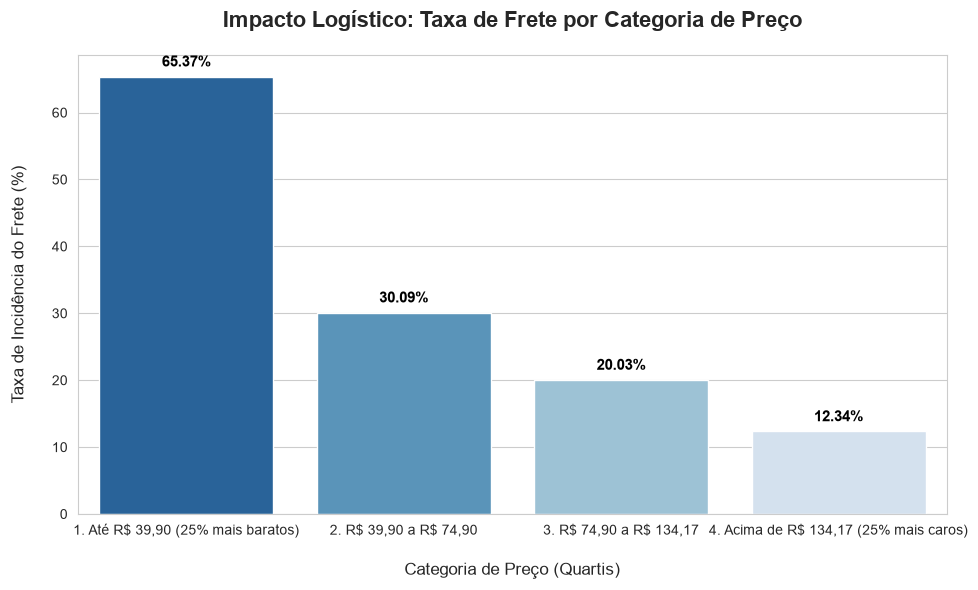

In [615]:
# 1. Nomeando as faixas (usando \\$ para evitar o modo matemático)
nomes_faixas= [
    '1. Até R\\$ 39,90 (25% mais baratos)', 
    '2. R\\$ 39,90 a R\\$ 74,90', 
    '3. R\\$ 74,90 a R\\$ 134,17', 
    '4. Acima de R\\$ 134,17 (25% mais caros)'
]

# 2. Aplicando a classificação dos nomes das faixas na base de dados (como uma nova coluna)
df_faturamento['categoria_preco'] = pd.cut(df_faturamento['price'], bins=faixas, labels=nomes_faixas)
prova_estatistica = df_faturamento.groupby('categoria_preco', observed=True)['taxa_frete'].mean()

# 3. Preparando os dados para o gráfico
dados_grafico = prova_estatistica.reset_index()

# 4. Desenhando o Gráfico
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

grafico = sns.barplot(
    data=dados_grafico,
    x='categoria_preco',
    y='taxa_frete',
    hue='categoria_preco',  # Adicionando cores diferentes para cada categoria
    dodge=False, #Desativando o deslocamento das barras para que fiquem lado a lado (mais largas)
    legend=False,           # Removendo a legenda para evitar repetição
    palette='Blues_r'       # CORREÇÃO: Apenas o nome da paleta entre aspas!
)

plt.title('Impacto Logístico: Taxa de Frete por Categoria de Preço', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('\nCategoria de Preço (Quartis)', fontsize=12)
plt.ylabel('Taxa de Incidência do Frete (%)\n', fontsize=12)

for barra in grafico.patches:
    grafico.annotate(f"{barra.get_height():.2f}%",
                     (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                     ha='center', va='bottom',
                     fontsize=11, fontweight='bold', color='black',
                     xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

In [616]:
# Verificando os nomes das colunas disponíveis para a análise geográfica
df_faturamento.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date',
       'price', 'freight_value', 'taxa_frete', 'categoria_preco'],
      dtype='str')

In [617]:
# 1. Carregando a tabela de clientes da Olist
df_clientes = pd.read_csv('../data/olist_customers_dataset.csv')

# 2. Fazendo o "PROCV" (Merge): Cruzando a tabela financeira com a de clientes
# Utilizando o 'customer_id' como a chave que liga as duas tabelas
df_faturamento_estado = pd.merge(
    df_faturamento, 
    df_clientes[['customer_id', 'customer_state']], # Puxando apenas o ID e o Estado para não pesar a memória
    on='customer_id', 
    how='left'
)

# 3. Exibindo as primeiras linhas para confirmar se a coluna 'customer_state' apareceu no final
display(df_faturamento_estado.head())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,taxa_frete,categoria_preco,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,29.076359,"1. Até R\$ 39,90 (25% mais baratos)",SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,19.174389,"3. R\$ 74,90 a R\$ 134,17",BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,12.020013,"4. Acima de R\$ 134,17 (25% mais caros)",GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,60.444444,"2. R\$ 39,90 a R\$ 74,90",RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,43.819095,"1. Até R\$ 39,90 (25% mais baratos)",SP


In [618]:
# 1. Agrupando por Estado utilizando a Mediana (protegido contra outliers)
analise_estado = df_faturamento_estado.groupby('customer_state').agg(
    taxa_frete_mediana=('taxa_frete', 'median'),
    volume_pedidos=('order_id', 'count')
).sort_values(by='taxa_frete_mediana', ascending=False).reset_index()

# Arredondando os valores para 2 casas decimais
analise_estado['taxa_frete_mediana'] = analise_estado['taxa_frete_mediana'].round(2)

# 2. Exibindo os 10 estados com a maior mediana de frete
display(analise_estado.head(10))

,customer_state,taxa_frete_mediana,volume_pedidos
0,AM,41.35,163
1,RO,40.00,273
2,MA,39.22,800
3,PB,37.09,586
4,TO,36.63,310
5,RR,36.26,46
6,AC,34.84,91
7,SE,34.83,375
8,PA,34.26,1054
9,PI,33.23,523


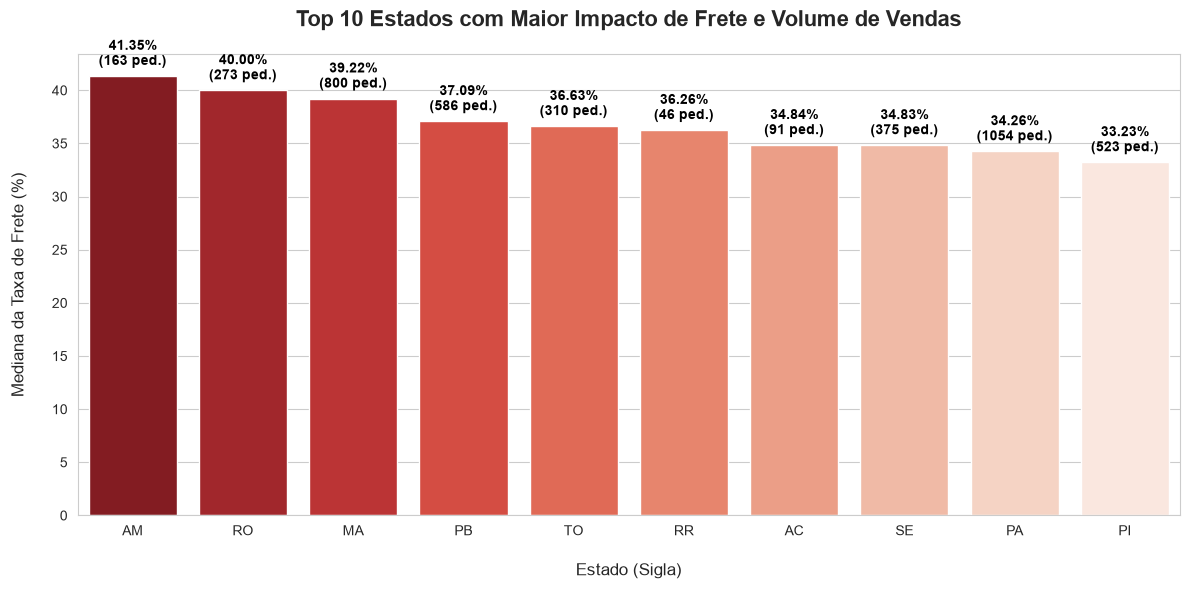

In [619]:
# 1. Separando apenas o Top 10
dados_grafico_estado = analise_estado.head(10)

# 2. Configurando o tamanho da tela e o fundo
plt.figure(figsize=(12, 6))
sns.set_style("whitegrid")

# 3. Desenhando o Gráfico de Colunas
grafico_estados = sns.barplot(
    data=dados_grafico_estado,
    x='customer_state',
    y='taxa_frete_mediana',
    hue='customer_state',
    legend=False,
    palette='Reds_r'
)

# 4. Inserindo Títulos e Eixos
plt.title('Top 10 Estados com Maior Impacto de Frete e Volume de Vendas', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('\nEstado (Sigla)', fontsize=12)
plt.ylabel('Mediana da Taxa de Frete (%)\n', fontsize=12)

# 5. Adicionando Rótulos Duplos (Taxa + Volume) usando enumerate
for i, barra in enumerate(grafico_estados.patches):
    # Capturando o volume exato daquele estado na tabela
    volume = dados_grafico_estado['volume_pedidos'].iloc[i]
    
    # Criando o texto com a taxa em cima e o volume (ped.) embaixo
    texto_rotulo = f"{barra.get_height():.2f}%\n({volume} ped.)"
    
    grafico_estados.annotate(texto_rotulo,
                     (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                     ha='center', va='bottom',
                     fontsize=10, fontweight='bold', color='black',
                     xytext=(0, 5), textcoords='offset points')

# 6. Ajustando e exibindo
plt.tight_layout()
plt.show()

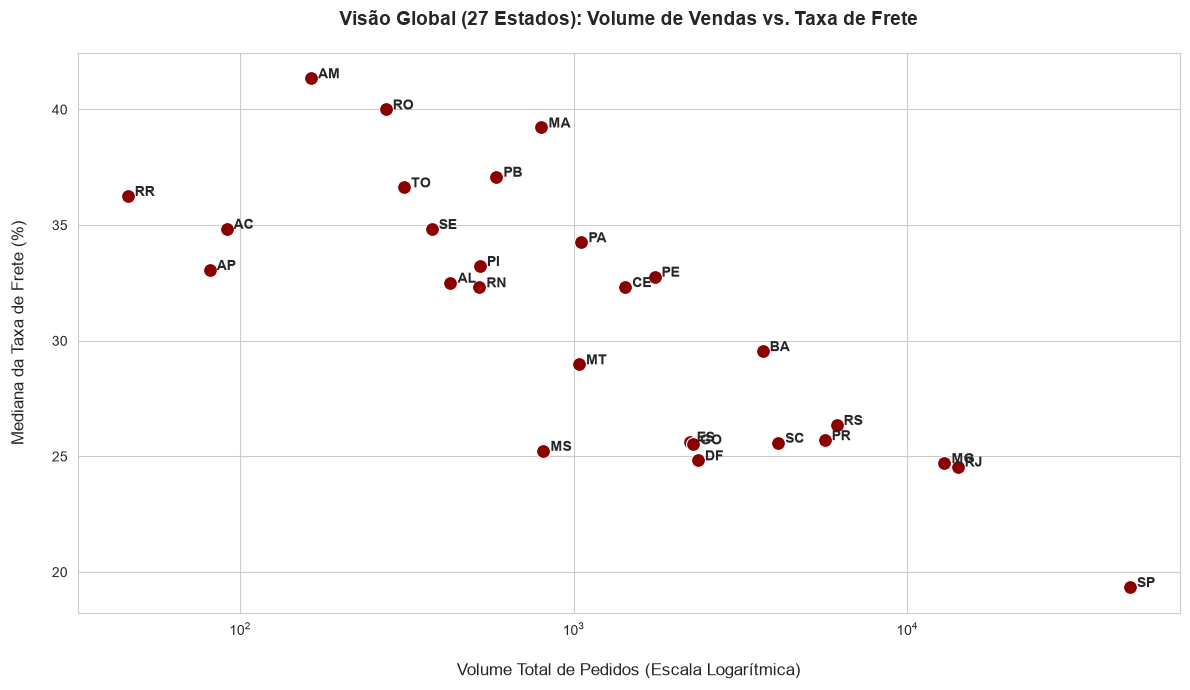

In [620]:
plt.figure(figsize=(12, 7))
sns.set_style("whitegrid")

# Configurando a tabela em formato scatterplot (dispersão) para analisar os 27 estados
sns.scatterplot(
    data=analise_estado, 
    x='volume_pedidos', 
    y='taxa_frete_mediana',
    color='darkred', 
    s=100 # Tamanho dos pontos
)

# Inserindo a sigla de cada estado ao lado dos pontos
for i in range(analise_estado.shape[0]):
    plt.text(
        x=analise_estado['volume_pedidos'][i] * 1.05, 
        y=analise_estado['taxa_frete_mediana'][i], 
        s=analise_estado['customer_state'][i],
        fontsize=10, fontweight='bold'
    )

plt.title('Visão Global (27 Estados): Volume de Vendas vs. Taxa de Frete', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('\nVolume Total de Pedidos (Escala Logarítmica)', fontsize=12)
plt.ylabel('Mediana da Taxa de Frete (%)\n', fontsize=12)

# Escala logarítmica no eixo X
plt.xscale('log') 

plt.tight_layout()
plt.show()

## 6. Análise Geográfica: Onde o Frete Pesa Mais?
Após verificar um frete é alto para os produtos de baixo valor, o passo seguinte foi identificar o foco geográfico deste problema. Para garantir o rigor estatístico, utilizei a mediana em vez da média, protegendo assim a análise contra outliers (entregas pontuais com custos logísticos que distorceriam os números).

O cruzamento dos dados revela uma margem alta do frete nas regiões Norte e Nordeste:

**O Extremo da Taxa**: O Amazonas (AM) e Rondônia (RO) lideram o impacto relativo, com os clientes pagando 40% do valor do produto apenas em transporte.

**Estados com pouco volume de vendas**: Estados como o Amapá (AP) e Roraima (RR) possuem fretes altos, mas volumes de vendas ainda baixos (menos de 100 pedidos). 

**Estados com alto volume de vendas e custo alto do frete**: Os estados do Pará (PA) e Maranhão (MA) combinam taxas de incidência de frete com custo alto para o produto (34,26% e 39,22%) com os maiores volumes de pedidos do Top 10 (1.054 e 800 pedidos, respectivamente).

In [621]:
# 1. Carregando a tabela de avaliações (reviews)
df_reviews = pd.read_csv('../data/olist_order_reviews_dataset.csv')

# Removendo possíveis avaliações duplicadas do mesmo pedido para não distorcer a base
df_reviews_unica = df_reviews.drop_duplicates(subset=['order_id'])

# 2. Fazendo o Merge: Cruzando a base atual com as notas usando o 'order_id'
df_faturamento_reviews = pd.merge(
    df_faturamento_estado, 
    df_reviews_unica[['order_id', 'review_score']],
    on='order_id', 
    how='left'
)

# 3. Calculando a Mediana do Frete, Volume de Vendas e a Nota Média por Estado
analise_estado_reviews = df_faturamento_reviews.groupby('customer_state').agg(
    taxa_frete_mediana=('taxa_frete', 'median'),
    volume_pedidos=('order_id', 'count'),
    nota_media_cliente=('review_score', 'mean') # Média das notas de 1 a 5
).sort_values(by='taxa_frete_mediana', ascending=False).reset_index()

# Arredondando os valores para 2 casas decimais
analise_estado_reviews['taxa_frete_mediana'] = analise_estado_reviews['taxa_frete_mediana'].round(2)
analise_estado_reviews['nota_media_cliente'] = analise_estado_reviews['nota_media_cliente'].round(2)

# 4. Exibindo o Top 10 estados com frete mais caro e suas respectivas notas
display(analise_estado_reviews.head(10))

,customer_state,taxa_frete_mediana,volume_pedidos,nota_media_cliente
0,AM,41.35,163,4.11
1,RO,40.00,273,4.07
2,MA,39.22,800,3.76
3,PB,37.09,586,4.04
4,TO,36.63,310,4.16
5,RR,36.26,46,3.89
6,AC,34.84,91,4.13
7,SE,34.83,375,3.90
8,PA,34.26,1054,3.84
9,PI,33.23,523,3.96


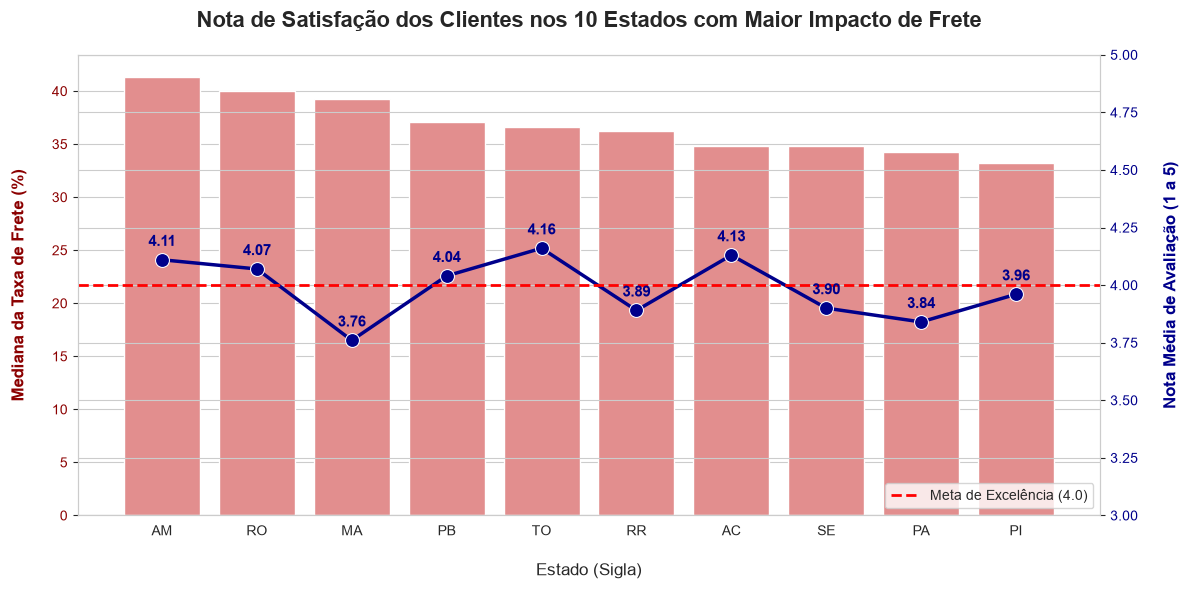

In [622]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filtrar os 10 estados com maior incidência de frete
dados_grafico_reviews = analise_estado_reviews.head(10)

# 2. Configurar a figura e o eixo principal
fig, ax1 = plt.subplots(figsize=(12, 6))
sns.set_style("whitegrid")

# 3. Eixo 1 (Esquerda): Barras com a Mediana da Taxa de Frete
cor_frete = 'lightcoral'
sns.barplot(
    data=dados_grafico_reviews,
    x='customer_state',
    y='taxa_frete_mediana',
    color=cor_frete,
    ax=ax1
)
ax1.set_ylabel('Mediana da Taxa de Frete (%)\n', fontsize=12, color='darkred', fontweight='bold')
ax1.set_xlabel('\nEstado (Sigla)', fontsize=12)
ax1.tick_params(axis='y', labelcolor='darkred')

# 4. Eixo 2 (Direita): Linha com a Nota Média de Avaliação
ax2 = ax1.twinx() # Cria um segundo eixo Y partilhando o mesmo eixo X
cor_nota = 'darkblue'
sns.lineplot(
    data=dados_grafico_reviews,
    x='customer_state',
    y='nota_media_cliente',
    color=cor_nota,
    marker='o',
    linewidth=2.5,
    markersize=10,
    ax=ax2
)
ax2.set_ylabel('\nNota Média de Avaliação (1 a 5)', fontsize=12, color=cor_nota, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=cor_nota)
ax2.set_ylim(3.0, 5.0) # Foca a escala visual nas variações relevantes

# 5. Adicionar a Linha de Quebra (Meta de Excelência 4.0)
ax2.axhline(y=4.0, color='red', linestyle='--', linewidth=2, label='Meta de Excelência (4.0)')
ax2.legend(loc='lower right')

# 6. Adicionar os rótulos numéricos das notas
for i, nota in enumerate(dados_grafico_reviews['nota_media_cliente']):
    ax2.annotate(f"{nota:.2f}",
                 (i, nota),
                 textcoords="offset points",
                 xytext=(0,10),
                 ha='center', fontsize=11, fontweight='bold', color=cor_nota)

plt.title('Nota de Satisfação dos Clientes nos 10 Estados com Maior Impacto de Frete', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

In [623]:
# 1. Calculando a Média Nacional de Satisfação da Olist
media_nacional = df_faturamento_reviews['review_score'].mean()

# 2. Calculando a Média de Satisfação em São Paulo (estado com maior volume e menor frete)
media_sp = df_faturamento_reviews[df_faturamento_reviews['customer_state'] == 'SP']['review_score'].mean()

# 3. Média de satisfação da Olist
print("--- Média de Satisfação ---")
print(f"Média Nacional da Olist: {media_nacional:.2f}")
print(f"Média em São Paulo (SP): {media_sp:.2f}")
print(f"Média no Pará (PA): 3.84")
print(f"Média no Maranhão (MA): 3.76")

--- Média de Satisfação ---
Média Nacional da Olist: 4.08
Média em São Paulo (SP): 4.18
Média no Pará (PA): 3.84
Média no Maranhão (MA): 3.76


### 7. O Preço do Frete e o Nível de Satisfação do Cliente (Reviews)

Depois de analisar o valor alto dos fretes nos diferentes estados, para identificar os pontos com possibilidade de melhoria e expansão, cruzei os dados geográficos com a base de avaliações dos consumidores (`olist_order_reviews_dataset`). O objetivo foi verificar o nível de satisfação nos estados. 

Os dados mostraram que:

Apesar de possuírem o maior número de pedidos nas regiões analisadas com fretes mais altos, o **Maranhão (MA)** e o **Pará (PA)** apresentam notas médias de **3,76** e **3,84**, respectivamente.

A média nacional de satisfação da Olist é de **4,08**, atingindo o pico de **4,18** em São Paulo. O MA e do PA operam abaixo da régua.

**Conclusão:** O alto volume de vendas mesmo com o alto valor do frete, mostram que o Maranhão e o Pará são consumidores em potencial, porém além do valor do frete (que conforme no levantamento da ABIACOM pode ser um risco),as notas nesses estados estão abaixo da média da Olist.


In [624]:
# 1. Verificando os textos para filtrar a insatisfação dos clientes do PA e MA
df_faturamento_textos = pd.merge(
    df_faturamento_estado,
    df_reviews_unica[['order_id', 'review_score', 'review_comment_message']],
    on='order_id',
    how='left'
)
estados_alvo = ['PA', 'MA']
clientes_insatisfeitos = df_faturamento_textos[
    (df_faturamento_textos['customer_state'].isin(estados_alvo)) &
    (df_faturamento_textos['review_score'] <= 3)
].dropna(subset=['review_comment_message']).copy() # .copy() evita alertas do Pandas

# 2. Definindo listas de palavras-chave separadas para Custo e Prazo
palavras_custo = ['frete', 'caro', 'valor', 'preço', 'abusivo', 'cobrado']
palavras_atraso = ['atraso', 'demora', 'prazo', 'não chegou', 'aguardando', 'esperando', 'recebi']

# 3. Funções de categorização
def reclamou_custo(texto):
    texto_limpo = str(texto).lower()
    return any(palavra in texto_limpo for palavra in palavras_custo)

def reclamou_atraso(texto):
    texto_limpo = str(texto).lower()
    return any(palavra in texto_limpo for palavra in palavras_atraso)

# 4. Aplicando as funções na base de clientes insatisfeitos do PA e MA
clientes_insatisfeitos['reclamou_custo'] = clientes_insatisfeitos['review_comment_message'].apply(reclamou_custo)
clientes_insatisfeitos['reclamou_atraso'] = clientes_insatisfeitos['review_comment_message'].apply(reclamou_atraso)

# 5. Somando os cenários
total_textos = len(clientes_insatisfeitos)
total_custo = clientes_insatisfeitos['reclamou_custo'].sum()
total_atraso = clientes_insatisfeitos['reclamou_atraso'].sum()
total_ambos = clientes_insatisfeitos[(clientes_insatisfeitos['reclamou_custo'] == True) & 
                                     (clientes_insatisfeitos['reclamou_atraso'] == True)].shape[0]

# 6. Exibindo os resultados refinados
print("--- Causa raiz das reclamações no PA e MA (DETALHADA) ---")
print(f"Total de avaliações negativas com texto escrito: {total_textos}")
print(f"Menções exclusivas ou parciais a FRETE/CUSTO: {total_custo}")
print(f"Menções exclusivas ou parciais a ATRASO/PRAZO: {total_atraso}")
print(f"Clientes que reclamaram de AMBOS na mesma frase: {total_ambos}\n")

--- Causa raiz das reclamações no PA e MA (DETALHADA) ---
Total de avaliações negativas com texto escrito: 371
Menções exclusivas ou parciais a FRETE/CUSTO: 9
Menções exclusivas ou parciais a ATRASO/PRAZO: 176
Clientes que reclamaram de AMBOS na mesma frase: 2



In [625]:
# 1. Carregando a base de pedidos (onde estão as datas)
df_pedidos = pd.read_csv('../data/olist_orders_dataset.csv')

# 2. Convertendo as colunas de data para o formato datetime
df_pedidos['order_purchase_timestamp'] = pd.to_datetime(df_pedidos['order_purchase_timestamp'])
df_pedidos['order_delivered_customer_date'] = pd.to_datetime(df_pedidos['order_delivered_customer_date'])

# 3. Calculando o tempo de entrega real em dias
df_pedidos['tempo_entrega_dias'] = (df_pedidos['order_delivered_customer_date'] - df_pedidos['order_purchase_timestamp']).dt.days

# 4. Cruzando as datas com a nossa base atual
df_faturamento_tempo = pd.merge(
    df_faturamento_reviews, # Usando a base que já tem frete e notas
    df_pedidos[['order_id', 'tempo_entrega_dias']],
    on='order_id',
    how='left'
)

# 5. Calculando as medianas nacionais e estaduais
mediana_tempo_nacional = df_faturamento_tempo['tempo_entrega_dias'].median()
mediana_tempo_sp = df_faturamento_tempo[df_faturamento_tempo['customer_state'] == 'SP']['tempo_entrega_dias'].median()
mediana_tempo_pa = df_faturamento_tempo[df_faturamento_tempo['customer_state'] == 'PA']['tempo_entrega_dias'].median()
mediana_tempo_ma = df_faturamento_tempo[df_faturamento_tempo['customer_state'] == 'MA']['tempo_entrega_dias'].median()

# 6. Exibindo a realidade dos dados
print("--- REALIDADE LOGÍSTICA: TEMPO DE ENTREGA (MEDIANA EM DIAS) ---")
print(f"Média Nacional: {mediana_tempo_nacional:.0f} dias")
print(f"São Paulo (SP): {mediana_tempo_sp:.0f} dias")
print(f"Pará (PA): {mediana_tempo_pa:.0f} dias")
print(f"Maranhão (MA): {mediana_tempo_ma:.0f} dias")

--- REALIDADE LOGÍSTICA: TEMPO DE ENTREGA (MEDIANA EM DIAS) ---
Média Nacional: 10 dias
São Paulo (SP): 7 dias
Pará (PA): 21 dias
Maranhão (MA): 19 dias



### 8. A Realidade Logística no Norte e Nordeste

Após constatar a queda na satisfação dos clientes no Pará e no Maranhão, decidi analisar duas frentes: a mineração dos textos das avaliações e o cálculo exato do tempo de entrega. O objetivo foi quantificar o que gera mais atrito: o peso financeiro (frete) ou o peso operacional (tempo).

* **A Voz do Cliente:** A mineração de 371 avaliações negativas (notas 1 a 3 com texto) no PA e MA revelou que apenas 9 queixas focaram no custo do frete, enquanto **176 menções** falam sobre os atrasos e o prazo de entrega.
Enquanto a mediana de entrega no estado de São Paulo é de apenas **7 dias**, o cliente no Maranhão espera **19 dias** e no Pará **21 dias** (muito acima da média nacional de 10 dias).

**Conclusão:** Os dados mostram que o que impacta a nota do Norte/Nordeste não é o valor do frete, o consumidor destes locais aceitam pagar o frete mais caro, mas se demonstram insatisfeitos com o nível de serviço logístico da plataforma. 

In [626]:
# 1. Carregar a base de clientes (que contém o ID único por pessoa: customer_unique_id)
df_clientes_recompra = pd.read_csv('../data/olist_customers_dataset.csv')

# 2. Contar quantas compras cada pessoa fez (agrupando pelo ID único)
compras_por_pessoa = df_clientes_recompra.groupby('customer_unique_id').size().reset_index(name='total_compras')

# 3. Marcar se o cliente fez mais de 1 compra (Recomprou = True)
compras_por_pessoa['recomprou'] = compras_por_pessoa['total_compras'] > 1

# 4. Trazer o estado do cliente de volta para a tabela
clientes_estado = df_clientes_recompra[['customer_unique_id', 'customer_state']].drop_duplicates(subset=['customer_unique_id'])
df_recompra_final = pd.merge(compras_por_pessoa, clientes_estado, on='customer_unique_id', how='left')

# 5. Calcular a média percentual de recompra por estado
taxa_recompra = df_recompra_final.groupby('customer_state')['recomprou'].mean() * 100
taxa_nacional = df_recompra_final['recomprou'].mean() * 100

# 6. Exibir os resultados matemáticos de perda de clientes
print("--- TAXA DE RECOMPRA ---")
print(f"Taxa de Recompra Nacional: {taxa_nacional:.2f}%")
print(f"Taxa de Recompra em São Paulo (SP): {taxa_recompra['SP']:.2f}%")
print(f"Taxa de Recompra no Pará (PA): {taxa_recompra['PA']:.2f}%")
print(f"Taxa de Recompra no Maranhão (MA): {taxa_recompra['MA']:.2f}%")

--- TAXA DE RECOMPRA ---
Taxa de Recompra Nacional: 3.12%
Taxa de Recompra em São Paulo (SP): 3.24%
Taxa de Recompra no Pará (PA): 2.53%
Taxa de Recompra no Maranhão (MA): 2.34%


## 9. Avaliação de Impacto: Comportamento de Recompra

Cenário Nacional: A taxa de recompra no Brasil é de 3,12%, atingindo 3,24% em São Paulo (local com logística ágil e frete reduzido).

Cenário Norte/Nordeste: O Maranhão e o Pará registram taxas de recompra de 2,34% e 2,53%, respectivamente.

Sendo assim os dados mostram que a taxa de recompra é maior onde o frete é baixo e as entregas são ageis, mas são menores onde os fretes são mais caros e demorados. 